In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv(r'C:\Users\matti\OneDrive\Desktop\Python_statistic\Iris.csv')

### Exploring the Iris Dataset

In [4]:
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


The first step was to explore the Iris dataset using the head() method in pandas, which displays the first five observations and provided an initial overview of the dataset structure and the variables available for the classification task.

The dataset contains four numerical features describing the dimensions of the sepals and petals, while the species column represents the target variable.


### Checking the Dataset Structure

In [3]:
# Display the dataset information
print(df.shape)
df.info()

(150, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB


The output also showed that all five columns contain 150 non-null values, meaning that there are no missing values in the dataset.

The four measurement features use the float64 data type, while the species column contains categorical labels.


### Identifying the Target Classes

In [5]:
# Display the available species
print(df['species'].unique())

['setosa' 'versicolor' 'virginica']


The dataset contains three species: setosa, versicolor and virginica. This confirmed that the task is a multiclass classification problem, in which the model must predict one of three possible classes. 

### Separating Features and Target Variable

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [7]:
# Separate the features (X) and the target (y)
X = df.drop('species', axis=1)
y = df['species']

The dataset was separated into input features (X) and a target variable (y).

### Splitting the Dataset into Training and Test Sets

In [8]:
# Split the dataset into training and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=101,
    stratify=y
)


In [11]:
print({'Xtrain' :X_train.shape,
       'Xtest' : X_test.shape,
       'ytrain' : y_train.shape,
       'ytest' : y_test.shape})

{'Xtrain': (105, 4), 'Xtest': (45, 4), 'ytrain': (105,), 'ytest': (45,)}


The dataset was divided into training and test sets using the train_test_split() function from scikit-learn. The test_size=0.3 parameter allocated 70% of the observations to the training set and 30% to the test set, resulting in 105 training observations and 45 test observations.

The stratify=y parameter was used to maintain the proportion of the three species in both subsets ensuring that each species was represented equally during training and evaluation

In [9]:
# Standardise the features
scaler = StandardScaler()

X_scaled_tr = scaler.fit_transform(X_train)
X_scaled_tst = scaler.transform(X_test)

In [12]:
X_scaled_tr

array([[ 0.31214394, -0.37434547,  0.54723611,  0.25913981],
       [ 2.49715154,  1.64712006,  1.52307671,  1.0478262 ],
       [ 0.9190905 , -0.37434547,  0.48983372,  0.12769208],
       [-1.2659171 , -0.14973819, -1.34704272, -1.18678523],
       [-0.05202399, -0.82356003,  0.77684566,  0.91637847],
       [-0.29480261, -0.37434547, -0.08419017,  0.12769208],
       [ 0.43353325, -1.94659643,  0.43243133,  0.39058754],
       [-0.41619192,  2.54554918, -1.34704272, -1.31823296],
       [-1.14452779, -0.14973819, -1.34704272, -1.31823296],
       [ 1.04047981, -0.14973819,  0.83424805,  1.44216939],
       [-0.53758124,  0.74869094, -1.17483556, -1.31823296],
       [ 0.55492257,  0.52408365,  1.29346716,  1.70506485],
       [-1.75147435, -0.37434547, -1.34704272, -1.31823296],
       [ 0.67631188, -0.59895275,  1.0638576 ,  1.17927393],
       [-0.05202399, -0.82356003,  0.77684566,  0.91637847],
       [ 0.43353325,  0.74869094,  0.94905283,  1.44216939],
       [ 1.28325843,  0.

### Defining the Hyperparameter Grid

In [13]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression

In [14]:
# Define the hyperparameter grid
param_grid = {
    'C': [0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000],
    'penalty': ['l1', 'l2'],
    'solver': ['saga']
}

The next step was to define a hyperparameter grid for the Logistic Regression model using GridSearchCV from scikit-learn. The aim was to compare different parameter combinations and identify a suitable configuration for the classification task.

The grid included eight values of C, two regularisation methods (l1 and l2) and the saga solver. The C parameter controls the strength of regularisation, while the penalty determines how the model coefficients are penalised. The saga solver was selected because it supports both L1 and L2 regularisation.

Overall, the grid contained 16 hyperparameter combinations. Evaluating these combinations through cross-validation would help identify a suitable model configuration before assessing its performance on the test set.

### Initialising the Logistic Regression Model

In [15]:
# Initialise logistic regression
log = LogisticRegression(max_iter=5000)

The Logistic Regression estimator was initialised using scikit-learn with the max_iter parameter set to 5000 defining the maximum number of iterations allowed for the optimisation algorithm to find the model coefficients.


### Hyperparameter Tuning Using Grid Search and Cross-Validation

In [16]:
# Create GridSearchCV
grid = GridSearchCV(
    log,
    param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

GridSearchCV was used to compare the Logistic Regression configurations defined in the hyperparameter grid. Five-fold cross-validation (cv=5) was selected, during which the model was trained on four subsets of the training data and evaluated on the remaining subset. 
Accuracy was the selected scoring metric with the mean accuracy across the five folds calculated for each hyperparameter combination.

In [17]:
# Train and compare the configurations
grid.fit(X_scaled_tr, y_train)

# Display the best hyperparameters
print("Best parameters:", grid.best_params_)
print("Best cross-validation accuracy:", grid.best_score_)

Best parameters: {'C': 1, 'penalty': 'l1', 'solver': 'saga'}
Best cross-validation accuracy: 0.9714285714285715


The configuration with the highest mean cross-validation accuracy was selected using best_params_, while best_score_ provided its corresponding mean accuracy.

The Grid Search selected a Logistic Regression configuration with C=1, L1 regularisation (penalty='l1') and the saga solver. This combination achieved a mean cross-validation accuracy of approximately 97.14% across the five folds.

### Generating Predictions on the Test Set

In [18]:
# Use the best configuration found by GridSearchCV
log_model = grid.best_estimator_

# Predict the species in the test set
prediction = log_model.predict(X_scaled_tst)


After hyperparameter tuning, the best Logistic Regression estimator was retrieved using the best_estimator_ from GridSearchCV. 

The fitted model was then used to predict the species in the scaled test set through the predict() method. These predictions were generated for observations that had not been used to fit the model or select its hyperparameters.



### Comparing Actual and Predicted Species

In [27]:
iris2 = df.copy()

# Get the index directly from your unscaled test set before scaling
index_pred = X_test.index.tolist()  # or simply: index_pred = X_test.index

iris_pred = iris2.loc[index_pred]

iris_pred['pred'] = prediction

iris_pred

,sepal_length,sepal_width,petal_length,petal_width,species,pred
149,5.9,3.0,5.1,1.8,virginica,virginica
135,7.7,3.0,6.1,2.3,virginica,virginica
70,5.9,3.2,4.8,1.8,versicolor,virginica
9,4.9,3.1,1.5,0.1,setosa,setosa
103,6.3,2.9,5.6,1.8,virginica,virginica
123,6.3,2.7,4.9,1.8,virginica,virginica
118,7.7,2.6,6.9,2.3,virginica,virginica
113,5.7,2.5,5.0,2.0,virginica,virginica
28,5.2,3.4,1.4,0.2,setosa,setosa
85,6.0,3.4,4.5,1.6,versicolor,versicolor


After generating the predictions, the original test observations were selected using their DataFrame indices. 

The predicted species were then added to a new column, pred, allowing the actual and predicted labels to be compared for each observation.

### Evaluating Test Accuracy

In [28]:
# Calculate test accuracy
print("Test accuracy:", log_model.score(X_scaled_tst, y_test))

Test accuracy: 0.9111111111111111


The fitted Logistic Regression model was evaluated on the test set using the score() method showing the model to achieve a test accuracy of 91.11%, indicating that it correctly classified 41 out of 45 observations.

This result was lower than the mean cross-validation accuracy of 97.14%, showing a difference between the model's performance during cross-validation and its performance on the separate test set highlighting the importance of evaluating a model on unseen data rather than relying only on cross-validation results.


# Evaluating the Classification Model

In [29]:
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

# Display the classification report
print(classification_report(y_test, prediction))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.92      0.80      0.86        15
   virginica       0.82      0.93      0.87        15

    accuracy                           0.91        45
   macro avg       0.92      0.91      0.91        45
weighted avg       0.92      0.91      0.91        45




The classification report was used to evaluate the Logistic Regression model on the test set showing the model to achieve an overall accuracy of 91.11%, with a macro-average F1-score of 0.91.

The results varied across the three species showing Setosa was classified with a precision and recall of 1.00, indicating that all its test observations were correctly identified. 
Versicolor, on the other hand, achieved a recall of 0.80, meaning that 20% of its actual observations were misclassified. 
Finally Virginica achieved a recall of approximately 0.93, with one of its 15 observations misclassified.

Therefore, the results indicate that the model was more effective at identifying setosa and virginica than versicolor. 

### Confusion Matrix and Classification Errors

In [30]:
cm1=confusion_matrix(y_test, prediction)
cm1

array([[15,  0,  0],
       [ 0, 12,  3],
       [ 0,  1, 14]], dtype=int64)

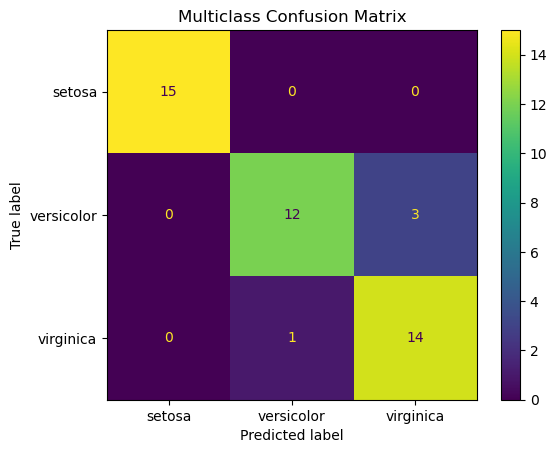

In [31]:
# Create the multiclass confusion matrix
cm = confusion_matrix(y_test, prediction, labels=log_model.classes_)

# Display the confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=log_model.classes_
)

disp.plot()
plt.title("Multiclass Confusion Matrix")
plt.show()

The confusion matrix was used to examine the correct and incorrect predictions made by the Logistic Regression model. 

The model correctly classified all 15 setosa observations, 12 of the 15 versicolor observations and 14 of the 15 virginica observations. 

The four misclassifications occurred between versicolor and virginica, with three versicolor observations predicted as virginica and one virginica observation predicted as versicolor.


In [32]:
species = ['setosa', 'versicolor', 'virginica']

results = []

for i, name in enumerate(species):

    # True Positives
    TP = cm1[i, i]

    # False Negatives: actual class i, predicted as another class
    FN = cm1[i, :].sum() - TP

    # False Positives: another actual class, predicted as class i
    FP = cm1[:, i].sum() - TP

    # True Negatives
    TN = cm1.sum() - TP - FN - FP

    # Calculate sensitivity and specificity
    sensitivity = TP / (TP + FN)
    specificity = TN / (TN + FP)

    results.append({
        'Species': name,
        'TP': TP,
        'FN': FN,
        'FP': FP,
        'TN': TN,
        'Sensitivity': sensitivity,
        'Specificity': specificity
    })

results_df = pd.DataFrame(results)

In [33]:
results_df

,Species,TP,FN,FP,TN,Sensitivity,Specificity
0,setosa,15,0,0,30,1.000000,1.000000
1,versicolor,12,3,1,29,0.800000,0.966667
2,virginica,14,1,3,27,0.933333,0.900000


Sensitivity, specificity, and Type I and Type II error rates were calculated for each species. 

Setosa achieved 100% sensitivity and specificity, with no classification errors.

Versicolor achieved 80% sensitivity and 96.67% specificity, resulting in a Type II error rate of 20%. 

Virginica achieved 93.33% sensitivity and 90% specificity, with Type I and Type II error rates of 10% and 6.67%, respectively.

These results show that the model identified setosa reliably but had more difficulty distinguishing between versicolor and virginica. 

In particular, the lower sensitivity for versicolor indicates that some observations belonging to this species were incorrectly classified as virginica.

### ROC Curve and Area Under the Curve (AUC)

In [34]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc, roc_auc_score

In [35]:
# Convert the multiclass target into a binary format (One-vs-Rest)
classes = log_model.classes_
y_test_bin = label_binarize(y_test, classes=classes)

The target variable was converted into a binary format using label_binarize() to support the multiclass ROC-AUC evaluation. 

The class labels were retrieved from the trained Logistic Regression model using classes_. 

This transformation allows a separate ROC curve and AUC score to be calculated for each Iris species.

In [36]:
# Obtain predicted probabilities for each species
y_score = log_model.predict_proba(X_scaled_tst)

The predict_proba() method was used to obtain the predicted probabilities for each Iris species on the test set.

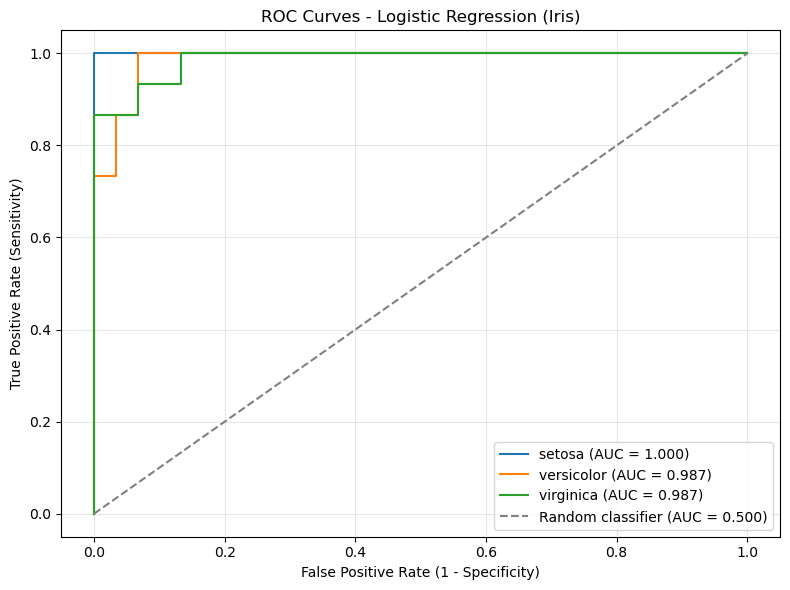

Macro-average ROC-AUC: 0.991


In [41]:
# Calculate and plot the ROC curve for each species
plt.figure(figsize=(8, 6))

for i, species in enumerate(classes):
    fpr, tpr, thresholds = roc_curve(
        y_test_bin[:, i],
        y_score[:, i]
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f'{species} (AUC = {roc_auc:.3f})'
    )

# Add the random classifier reference line
plt.plot([0, 1], [0, 1], linestyle='--',
         color='grey', label='Random classifier (AUC = 0.500)')

plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity)')
plt.title('ROC Curves - Logistic Regression (Iris)')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Calculate the macro-average ROC-AUC
macro_auc = roc_auc_score(
    y_test_bin,
    y_score,
    average='macro'
)

print(f'Macro-average ROC-AUC: {macro_auc:.3f}')

The ROC curve and Area Under the Curve (AUC) were used to further evaluate the Logistic Regression model. 

As the Iris dataset contains three classes, this helped to assess the model's ability to distinguish each species from the other two.
 
The AUC summarises the model's ability to discriminate between the classes, with a value of 1 indicating perfect discrimination and a value of 0.5 indicating performance equivalent to random ranking.

The predicted probabilities were obtained using the predict_proba() method, and a separate ROC curve and AUC score were calculated for each species. A macro-average ROC-AUC was also calculated to provide an overall measure that gives equal weight to each class.

These results complement the accuracy, classification report and confusion matrix by evaluating the model's discrimination across different thresholds rather than only its final predictions. The class-specific AUC values can also help identify differences in how effectively the model distinguishes between the three Iris species.

The ROC curve analysis produced a macro-average ROC-AUC of 0.991, indicating excellent discrimination between the three Iris species. 